# Chapitre 1 - Cours 5 : données, droit et société

Le dernier compromis du chapitre ne se joue pas entre deux technologies, mais entre les
besoins d'une entreprise et les droits des personnes dont elle traite les données. Le
livre insiste : les contraintes légales influencent désormais les **fondations** de la
conception des systèmes de données. Ce notebook couvre la section *Data Systems, Law, and
Society* et montre, par des expériences, pourquoi des exigences juridiques simples à
énoncer sont difficiles à implémenter.

**Plan.**

1. Une responsabilité qui dépasse l'entreprise : RGPD, décisions automatisées, et ce
   que cela implique techniquement.
2. Le droit à l'effacement face aux journaux immuables : compaction ou effacement
   cryptographique.
3. Effacer aussi les données dérivées : combien de temps une donnée survit-elle ?
4. La minimisation des données : coûts cachés du stockage, réidentification,
   pseudonymisation.
5. Résidence des données et normes du secteur.

In [1]:
import hashlib

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Une responsabilité qui dépasse l'entreprise (section *Data Systems, Law, and Society*)

Servir les besoins de son entreprise ne suffit plus : les ingénieurs de données ont aussi
une responsabilité envers la société. Deux constats du livre :

- **la loi** : depuis 2018, le RGPD (règlement général sur la protection des données,
  GDPR en anglais) donne aux résidents de nombreux pays européens davantage de contrôle et
  de droits sur leurs données personnelles ; des réglementations proches existent ailleurs
  (le CCPA en Californie), et les règles sur l'IA (le règlement européen sur l'IA)
  encadrent encore davantage l'usage des données personnelles ;
- **les effets sur les personnes**, même hors réglementation : les réseaux sociaux
  changent la manière de s'informer, donc les opinions et peut-être les élections ; des
  systèmes automatisés décident qui obtient un prêt, une assurance, un entretien
  d'embauche, ou qui est suspecté d'un délit.

Personne n'a besoin de devenir juriste, mais une culture de base en droit et en éthique
est aussi importante, selon le livre, qu'une culture de base en systèmes distribués. Le
schéma ci-dessous relie quelques principes juridiques aux mécanismes techniques qu'ils
exigent, et que les chapitres suivants permettent de construire.

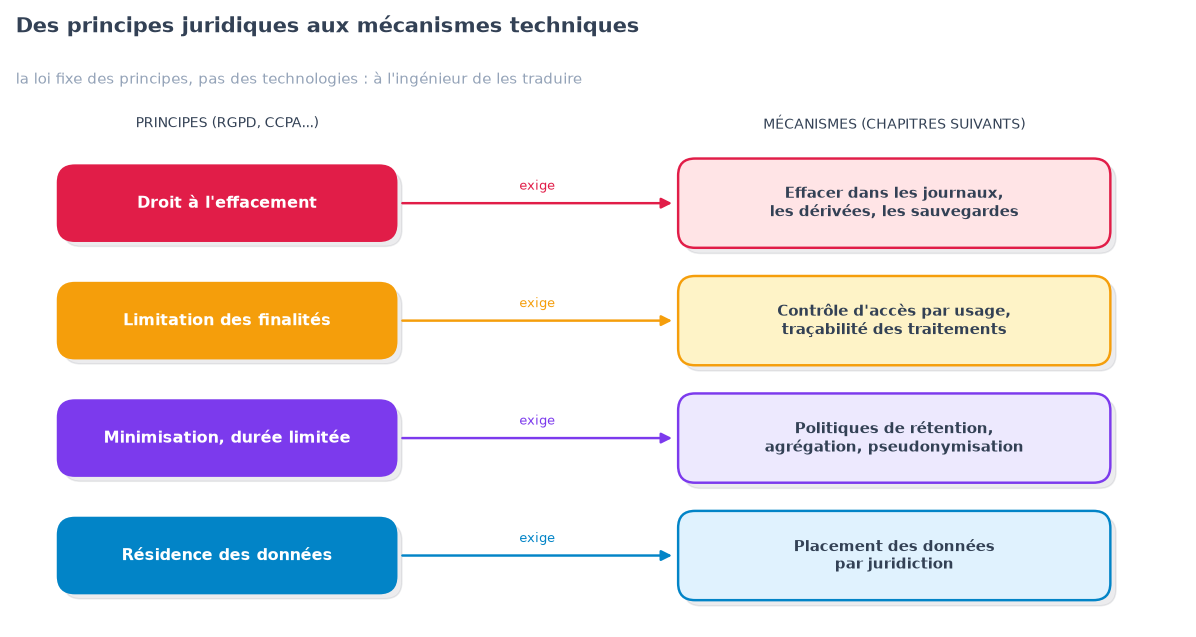

In [2]:
d = Diagram(12.5, 5.6, title="Des principes juridiques aux mécanismes techniques",
            subtitle="la loi fixe des principes, pas des technologies : à l'ingénieur de les traduire")
law = [("eff", "Droit à l'effacement", ROSE), ("fin", "Limitation des finalités", AMBER),
       ("min", "Minimisation, durée limitée", VIOLET), ("res", "Résidence des données", SKY)]
tech = [("t_eff", "Effacer dans les journaux,\nles dérivées, les sauvegardes"), ("t_fin", "Contrôle d'accès par usage,\ntraçabilité des traitements"),
        ("t_min", "Politiques de rétention,\nagrégation, pseudonymisation"), ("t_res", "Placement des données\npar juridiction")]
for i, ((k, t, c), (k2, t2)) in enumerate(zip(law, tech)):
    y = 4.5 - i * 1.25
    d.box(k, 2.3, y, t, color=c, w=3.6, h=0.8, filled=True)
    d.box(k2, 9.4, y, t2, color=c, w=4.6, h=0.95, fontsize=9.5)
    d.arrow(k, k2, "exige", color=c)
d.note(2.3, 5.35, "PRINCIPES (RGPD, CCPA...)", color=SLATE, style="normal")
d.note(9.4, 5.35, "MÉCANISMES (CHAPITRES SUIVANTS)", color=SLATE, style="normal")
d.show()

Le livre souligne qu'il n'existe pas aujourd'hui de liste claire des technologies ou
architectures « conformes au RGPD » : le règlement énonce volontairement des principes
généraux, sujets à interprétation, pour ne pas dépendre d'une technologie vite dépassée.
La conformité n'a donc pas de réponse simple ; regardons les cas les plus techniques.

> **À retenir.** Les systèmes de données sont soumis au droit (RGPD, CCPA, règles sur l'IA)
> et ont des effets sociaux réels. La loi fixe des principes ; les traduire en mécanismes
> techniques est un travail d'ingénierie, souvent difficile.

## 2. Le droit à l'effacement face aux journaux immuables (section *Data Systems, Law, and Society*)

Le RGPD donne à chacun le droit de faire effacer ses données sur demande (le « droit à
l'oubli »). Or beaucoup de systèmes de données reposent sur des structures **immuables**,
comme les **journaux en ajout seul** (« append-only logs ») : moteurs de stockage
(chapitre 4), réplication (chapitre 6), flux d'événements
(chapitre 12). Comment supprimer une donnée au milieu d'un fichier censé ne
jamais changer ?

Deux stratégies :

- la **compaction** : réécrire le journal sans les entrées de la personne
  (`ar.compact_without`). Correct, mais coûteux : chaque effacement réécrit tout ce qui
  reste ;
- l'**effacement cryptographique** (« crypto-shredding ») : chiffrer dès l'écriture les
  données de chaque personne avec **sa propre clé**, conservée à part ; effacer la
  personne revient à **détruire sa clé** (`ar.ShreddableLog`). Le journal reste
  intact, mais ses entrées deviennent illisibles.

Commençons par vérifier le principe sur un petit journal (le chiffrement par flot
utilisé ici, fondé sur SHA-256, est pédagogique et ne doit pas servir en production).

In [3]:
log = ar.ShreddableLog(seed=1)
events = [("alice", "connexion depuis 82.64.x.x"), ("bob", "achat : livre"), ("alice", "recherche : clinique"),
          ("carol", "achat : vélo"), ("alice", "position : 48.85, 2.35"), ("bob", "connexion")]
for u, e in events:
    log.append(u, e)
before = log.read()
size = log.size_bytes
rewritten = log.forget("alice")
after = log.read()
print(f"taille du journal : {size} octets avant, {log.size_bytes} octets après ; octets réécrits : {rewritten}")
pd.DataFrame({"utilisateur": [u for u, _ in log.entries],
              "octets stockés (extrait)": [blob[:8].hex() + "..." for _, blob in log.entries],
              "lisible avant": [t for _, t in before],
              "lisible après oubli d'alice": [t if u in log.keys else "(clé détruite)" for u, t in before]})

taille du journal : 103 octets avant, 103 octets après ; octets réécrits : 0


,utilisateur,octets stockés (extrait),lisible avant,lisible après oubli d'alice
0,alice,11068615533179bc...,connexion depuis 82.64.x.x,(clé détruite)
1,bob,9184d69cedc654ee...,achat : livre,achat : livre
2,alice,000c8b13533b73bb...,recherche : clinique,(clé détruite)
3,carol,076f729a24427c5f...,achat : vélo,achat : vélo
4,alice,02069b1242207fbd...,"position : 48.85, 2.35",(clé détruite)
5,bob,9388d093fc9e07a1...,connexion,connexion


Les octets chiffrés d'Alice sont toujours dans le journal (pas un octet n'a été réécrit,
la taille est inchangée), mais sans sa clé, plus personne ne peut les lire, y compris dans
les copies répliquées ou sauvegardées du journal, pourvu que la clé, elle, n'ait été
copiée nulle part. Comparons maintenant les **coûts** sur un journal réaliste : 10 millions
d'entrées de 200 octets (2 Go), et des demandes d'effacement qui arrivent au fil de l'eau.

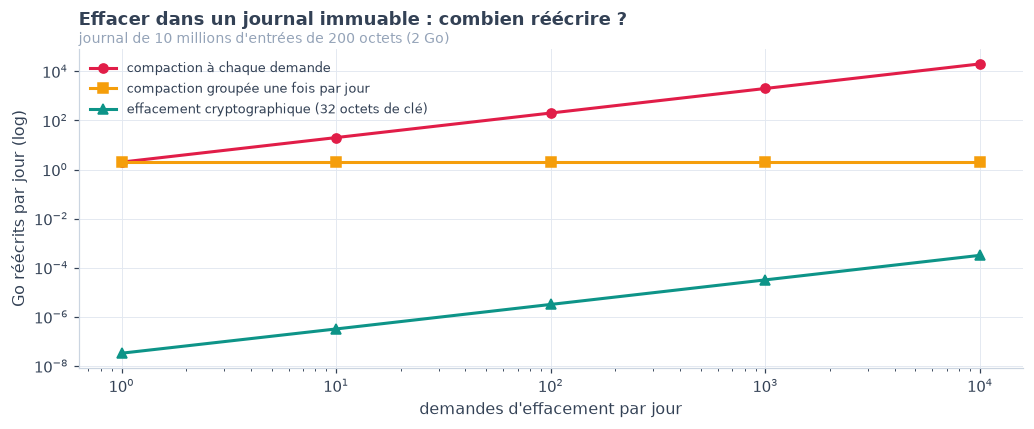

In [4]:
LOG_BYTES = 10_000_000 * 200
req_per_day = np.array([1, 10, 100, 1000, 10_000])
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.loglog(req_per_day, req_per_day * LOG_BYTES / 1e9, "o-", color=ROSE, label="compaction à chaque demande")
ax.loglog(req_per_day, np.full(req_per_day.size, LOG_BYTES / 1e9), "s-", color=AMBER,
          label="compaction groupée une fois par jour")
ax.loglog(req_per_day, req_per_day * 32 / 1e9 + 1e-9, "^-", color=TEAL, label="effacement cryptographique (32 octets de clé)")
ax.set_xlabel("demandes d'effacement par jour"); ax.set_ylabel("Go réécrits par jour (log)")
ax.set_title("Effacer dans un journal immuable : combien réécrire ?")
subtitle(ax, "journal de 10 millions d'entrées de 200 octets (2 Go)")
ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()

Compacter à chaque demande devient vite intenable (10 000 demandes par jour, 20 To
réécrits) ; grouper les compactions borne le coût à une réécriture par jour, au prix d'un
**délai** pendant lequel la donnée existe encore ; l'effacement cryptographique ne
supprime que quelques octets de clé. Il a toutefois ses propres exigences : gérer des
millions de clés de façon fiable (perdre la base de clés, c'est perdre toutes les
données), ne jamais les copier dans les sauvegardes ordinaires, et convaincre qu'un texte
chiffré dont la clé est détruite vaut effacement, ce qui reste une question
d'interprétation juridique.

> **À retenir.** Le droit à l'effacement heurte les structures immuables. La compaction
> réécrit le journal (coûteux, ou différé si on la groupe) ; l'effacement cryptographique
> détruit une clé par personne (immédiat, mais exige une gestion des clés irréprochable).

## 3. Effacer aussi les données dérivées (section *Data Systems, Law, and Society*)

Le livre pose une seconde question : comment effacer une donnée qui a été **incorporée
dans des jeux de données dérivés** (cours 2), par exemple les données d'entraînement d'un
modèle ? Le graphe de dérivation dit **où** chercher (tous les descendants de la source) ;
reste à savoir **quand** la donnée disparaît réellement de chacun. Chaque système dérivé
est reconstruit selon son propre rythme (un cache toutes les heures, un entrepôt chaque
nuit, un modèle chaque semaine, des sauvegardes conservées 30 jours) : une donnée effacée
à la source survit jusqu'à la prochaine reconstruction **après** que tous ses parents
l'ont eux-mêmes oubliée.

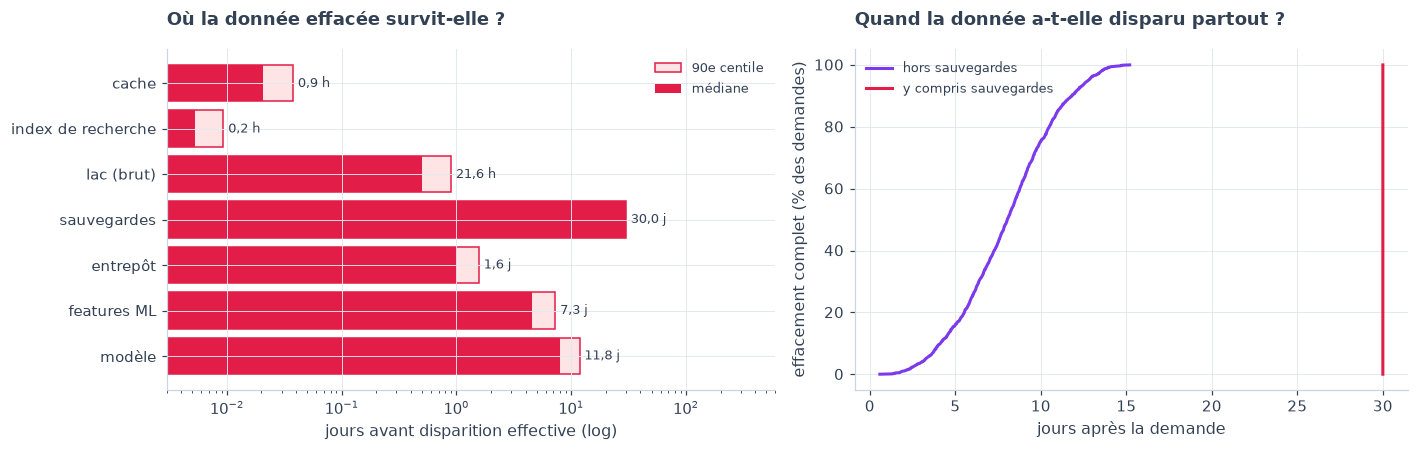

hors sauvegardes : médiane 8.0 j, maximum 15.2 j


In [5]:
G = nx.DiGraph()
period = {"base clients": 0, "cache": 1, "index de recherche": 0.25, "entrepôt": 24, "lac (brut)": 24,
          "features ML": 24 * 7, "modèle": 24 * 7, "sauvegardes": 24 * 30}
G.add_edges_from([("base clients", "cache"), ("base clients", "index de recherche"), ("base clients", "lac (brut)"),
                  ("lac (brut)", "entrepôt"), ("entrepôt", "features ML"), ("features ML", "modèle"),
                  ("base clients", "sauvegardes")])
order = ["base clients"] + ar.rebuild_order(G, "base clients")


def erase_times(seed):
    r = np.random.default_rng(seed)
    gone = {"base clients": 0.0}
    for n in order[1:]:
        ready = max(gone[p] for p in G.predecessors(n))
        if n == "sauvegardes":                       # une sauvegarde expire 30 jours après sa création
            gone[n] = ready + period[n]
        else:                                        # prochaine reconstruction, phase aléatoire
            phase = r.uniform(0, period[n])
            k = np.ceil((ready - phase) / period[n])
            gone[n] = phase + max(k, 0) * period[n]
            if gone[n] < ready:
                gone[n] += period[n]
    return gone


sims = pd.DataFrame([erase_times(s) for s in range(2000)])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
med = sims.median()[order[1:]] / 24
q90 = sims.quantile(0.9)[order[1:]] / 24
y = np.arange(len(med))
ax.barh(y, q90, color=LIGHT[ROSE], edgecolor=ROSE, label="90e centile")
ax.barh(y, med, color=ROSE, label="médiane")
ax.set_yticks(y); ax.set_yticklabels(med.index); ax.invert_yaxis(); ax.set_xscale("log")
for yi, v in zip(y, q90):
    lab = f"{v * 24:.1f} h" if v < 1 else f"{v:.1f} j"
    ax.text(v * 1.1, yi, lab.replace(".", ","), va="center", fontsize=8.5)
ax.set_xlabel("jours avant disparition effective (log)"); ax.set_title("Où la donnée effacée survit-elle ?")
ax.legend(fontsize=8.5, loc="upper right"); ax.set_xlim(0.003, 600)
ax = axes[1]
no_backup = sims.drop(columns=["sauvegardes"]).max(axis=1) / 24
for data, lab, c in [(no_backup, "hors sauvegardes", VIOLET), (sims.max(axis=1) / 24, "y compris sauvegardes", ROSE)]:
    xs = np.sort(data); ax.plot(xs, np.arange(1, xs.size + 1) / xs.size * 100, color=c, label=lab)
ax.set_xlabel("jours après la demande"); ax.set_ylabel("effacement complet (% des demandes)")
ax.set_title("Quand la donnée a-t-elle disparu partout ?"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()
print(f"hors sauvegardes : médiane {no_backup.median():.1f} j, maximum {no_backup.max():.1f} j")

Le cache et l'index oublient en moins d'une heure ; l'entrepôt en un ou deux jours ; mais
le **modèle** n'est réentraîné qu'après les features, elles-mêmes recalculées chaque
semaine à partir de l'entrepôt : il garde la trace de la personne jusqu'à deux semaines.
Et ce n'est qu'un « oubli » au sens où le modèle réentraîné n'a plus vu ces données ; un
modèle peut mémoriser des fragments de ses données d'entraînement, d'où les recherches sur
le « désapprentissage ». Les sauvegardes, conservées 30 jours, dominent tout. Rien
d'illégal à cela si c'est documenté et justifié, mais il faut **savoir** répondre à la
question « quand cette donnée aura-t-elle vraiment disparu ? », ce qui suppose un graphe
de dérivation explicite.

> **À retenir.** Effacer une personne, c'est l'effacer de toutes les données dérivées : le
> graphe de dérivation dit où, les rythmes de reconstruction disent quand. Modèles entraînés
> et sauvegardes sont les cas les plus lents et les plus délicats.

## 4. La minimisation des données (section *Data Systems, Law, and Society*)

On stocke une donnée parce qu'on pense que sa valeur dépasse son coût. Mais le coût ne se
limite pas à la facture du stockage : il faut y ajouter le **risque** de responsabilité et
d'atteinte à la réputation en cas de fuite ou de piratage, et le risque d'amendes si le
traitement s'avère non conforme. Les autorités peuvent aussi exiger la remise de données ;
et quand celles-ci révèlent des comportements pénalisés dans certains pays (le livre
cite l'homosexualité ou le recours à l'avortement), les conserver met réellement les
utilisateurs en danger : un historique d'adresses IP suffit à révéler des lieux visités.

Le principe de **minimisation** (en allemand *Datensparsamkeit*) en tire la conséquence :
certaines données ne valent pas d'être conservées. Il va à l'encontre de la philosophie
« big data » (tout garder au cas où) mais rejoint le RGPD : finalité précise et explicite,
pas de réutilisation pour une autre finalité, durée de conservation limitée au nécessaire.

**Un modèle de durée de conservation.** Une donnée d'activité a une valeur qui décroît
avec son âge (elle sert surtout récemment), alors que le risque qu'elle fait courir est à
peu près constant par jour de conservation (probabilité de fuite fois coût par
enregistrement exposé). En gardant chaque enregistrement $R$ jours, la valeur cumulée vaut
$v_0 \tau (1 - e^{-R/\tau})$ et le risque cumulé $\rho R$ : il existe une durée optimale
$R^* = \tau \ln(v_0 / \rho)$.

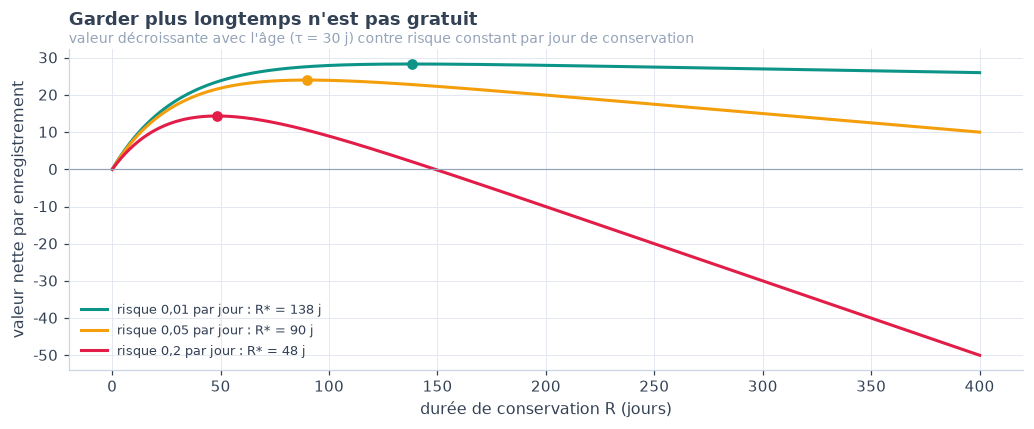

In [6]:
tau, v0 = 30.0, 1.0                                     # valeur : 1 unité/jour au début, décroît en 30 j
R = np.linspace(0, 400, 401)
fig, ax = plt.subplots(figsize=(9.5, 4))
for rho, c in [(0.01, TEAL), (0.05, AMBER), (0.2, ROSE)]:
    net = v0 * tau * (1 - np.exp(-R / tau)) - rho * R
    r_star = tau * np.log(v0 / rho)
    ax.plot(R, net, color=c, label=f"risque {rho:g} par jour : R* = {r_star:.0f} j".replace(".", ","))
    ax.plot(r_star, v0 * tau * (1 - np.exp(-r_star / tau)) - rho * r_star, "o", color=c)
ax.axhline(0, color=GRAY, lw=0.8)
ax.set_xlabel("durée de conservation R (jours)"); ax.set_ylabel("valeur nette par enregistrement")
ax.set_title("Garder plus longtemps n'est pas gratuit")
subtitle(ax, "valeur décroissante avec l'âge (τ = 30 j) contre risque constant par jour de conservation")
ax.legend(fontsize=8.5); plt.tight_layout(); plt.show()

Quand le risque par jour est faible, garder quelques mois se justifie ; quand il est élevé
(données sensibles, juridiction hostile), la durée optimale tombe à sept semaines environ,
et au-delà de cinq mois la valeur nette devient **négative** : la donnée coûte plus
qu'elle ne rapporte. Le modèle est simpliste, mais il rend explicite ce que la philosophie
« tout garder » ignore.

**Pourquoi « anonymiser » ne suffit pas.** On croit parfois neutraliser le risque en
retirant les noms. Deux expériences montrent la limite. D'abord, les traces de
localisation sont presque uniques : simulons 20 000 personnes qui fréquentent chacune
quelques lieux favoris (domicile, travail, loisirs) parmi 2 000 antennes de téléphonie, sur 24 tranches
horaires, et comptons la part des personnes identifiées de façon unique par $k$ points
(lieu, heure) tirés de leur trace.

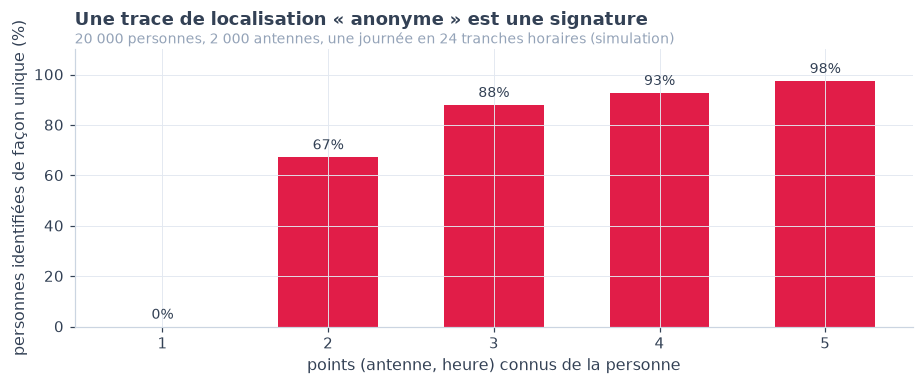

In [7]:
N_PEOPLE, N_ANT, H = 20_000, 2000, 24
w_ant = 1 / np.arange(1, N_ANT + 1) ** 0.6; w_ant /= w_ant.sum()     # antennes plus ou moins fréquentées
pick = lambda: rng.choice(N_ANT, N_PEOPLE, p=w_ant)
homes, works, fun = pick(), pick(), pick()
traces = np.empty((N_PEOPLE, H), dtype=np.int32)
for h in range(H):
    where = np.where((h >= 9) & (h < 18), works, homes)
    if 18 <= h < 22:
        where = np.where(rng.random(N_PEOPLE) < 0.5, fun, homes)
    jitter = rng.random(N_PEOPLE) < 0.15                       # déplacements occasionnels
    where = np.where(jitter, pick(), where)
    traces[:, h] = where

uniq = []
for k in range(1, 6):
    hits = 0
    sample = rng.choice(N_PEOPLE, 400, replace=False)
    for p in sample:
        hrs = rng.choice(H, k, replace=False)
        match = np.all(traces[:, hrs] == traces[p, hrs], axis=1)
        hits += match.sum() == 1
    uniq.append(hits / sample.size)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
b = ax.bar(range(1, 6), np.array(uniq) * 100, color=ROSE, width=0.6)
ax.bar_label(b, labels=[f"{u:.0%}" for u in uniq], padding=3, fontsize=9)
ax.set_xlabel("points (antenne, heure) connus de la personne"); ax.set_ylabel("personnes identifiées de façon unique (%)")
ax.set_ylim(0, 110); ax.set_title("Une trace de localisation « anonyme » est une signature")
subtitle(ax, "20 000 personnes, 2 000 antennes, une journée en 24 tranches horaires (simulation)")
plt.tight_layout(); plt.show()

Un seul point n'identifie personne (on partage son quartier avec beaucoup d'autres) ; mais
avec deux ou trois points connus (« elle est au bureau près de telle antenne à 10 h et
rentre chez elle près de telle autre à 20 h »), la grande majorité des traces devient
unique : retirer le nom ne rend pas la donnée anonyme. Ensuite, **hacher** un identifiant
n'est pas l'anonymiser : si l'espace des valeurs possibles est petit ou connu, il suffit
de hacher tous les candidats et de comparer.

In [8]:
hashed = {hashlib.sha256(f"client{i}@exemple.fr".encode()).hexdigest() for i in rng.choice(100_000, 50, replace=False)}
candidates = (f"client{i}@exemple.fr" for i in range(100_000))     # liste d'e-mails connue ou devinable
found = [c for c in candidates if hashlib.sha256(c.encode()).hexdigest() in hashed]
print(f"{len(found)} e-mails « pseudonymisés » retrouvés sur {len(hashed)} en hachant 100 000 candidats")

50 e-mails « pseudonymisés » retrouvés sur 50 en hachant 100 000 candidats


Les 50 e-mails sont retrouvés en une fraction de seconde. Le RGPD le reconnaît : des données
**pseudonymisées** restent des données personnelles. La vraie protection est de ne pas
collecter, d'agréger tôt, ou de supprimer.

> **À retenir.** Le coût d'une donnée inclut le risque qu'elle fait courir (fuite, amendes,
> réquisitions, danger pour les personnes). La minimisation (finalité précise, durée
> limitée) en découle. Retirer les noms ou hacher les identifiants ne suffit pas : les
> traces fines sont des signatures.

## 5. Résidence des données et normes du secteur (section *Data Systems, Law, and Society*)

Certaines lois exigent que les données des personnes d'une juridiction y soient stockées
et traitées (cours 4) ; leur portée varie (parfois seulement les données médicales ou
financières). Un service présent dans plusieurs juridictions doit donc **placer** ses
données, et ses répliques, selon des règles. Le diagramme espace-temps ci-dessous montre
un piège classique : une réplique de secours créée hors juridiction lors d'une
maintenance.

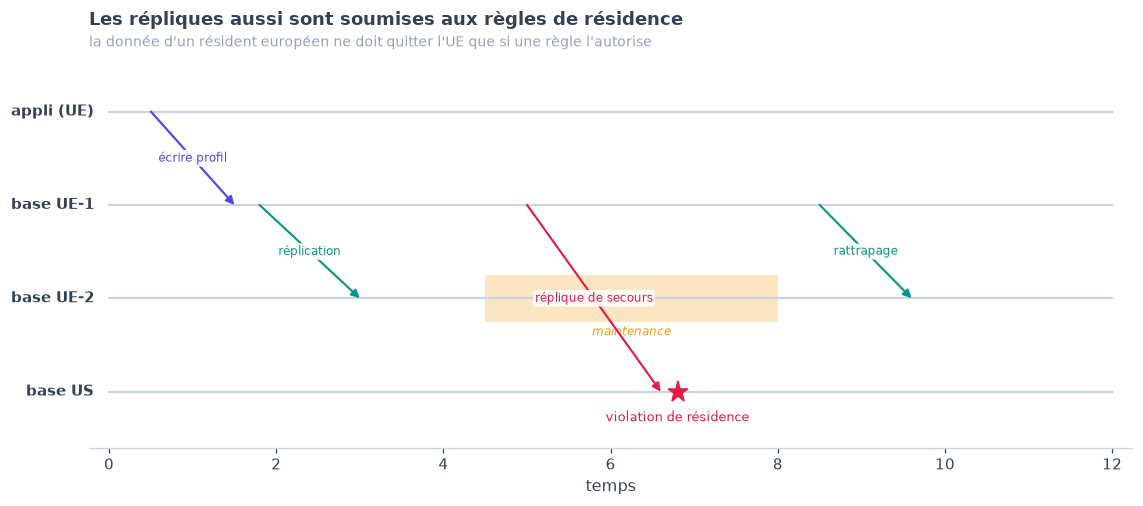

In [9]:
st = SpaceTime(["appli (UE)", "base UE-1", "base UE-2", "base US"], t_max=12, width=10.5,
               title="Les répliques aussi sont soumises aux règles de résidence",
               subtitle="la donnée d'un résident européen ne doit quitter l'UE que si une règle l'autorise")
st.msg("appli (UE)", 0.5, "base UE-1", 1.5, "écrire profil", color=INDIGO)
st.msg("base UE-1", 1.8, "base UE-2", 3.0, "réplication", color=TEAL)
st.span("base UE-2", 4.5, 8.0, "maintenance", color=AMBER)
st.msg("base UE-1", 5.0, "base US", 6.6, "réplique de secours", color=ROSE)
st.event("base US", 6.8, "violation de résidence", kind="star", color=ROSE)
st.msg("base UE-1", 8.5, "base UE-2", 9.6, "rattrapage", color=TEAL)
st.show()

Une vérification automatique est simple à écrire, à condition que le **placement soit une
donnée** (une table de règles) et non un choix implicite dispersé dans la configuration :

In [10]:
RULES = {"UE": {"UE"}, "US": {"US", "UE"}, "IN": {"IN"}}            # où peuvent résider les données de chaque juridiction
replicas = pd.DataFrame({"jeu de données": ["profils UE", "profils UE", "profils UE", "profils US", "profils US", "santé IN"],
                         "juridiction": ["UE", "UE", "UE", "US", "US", "IN"],
                         "réplique en": ["UE", "UE", "US", "US", "UE", "UE"]})
replicas["conforme"] = [r in RULES[j] for j, r in zip(replicas["juridiction"], replicas["réplique en"])]
replicas["conforme"] = replicas["conforme"].map({True: "oui", False: "NON : violation"})
replicas

,jeu de données,juridiction,réplique en,conforme
0,profils UE,UE,UE,oui
1,profils UE,UE,UE,oui
2,profils UE,UE,US,NON : violation
3,profils US,US,US,oui
4,profils US,US,UE,oui
5,santé IN,IN,UE,NON : violation


Le livre mentionne enfin que les entreprises s'imposent aussi des règles : les réseaux de
cartes bancaires exigent des prestataires de paiement le respect des normes **PCI**, vérifié
par des audits indépendants fréquents ; beaucoup d'acheteurs de logiciels exigent de leurs
fournisseurs une conformité **SOC 2 (type 2)**, elle aussi auditée. Le chapitre
14 approfondira l'éthique et la conformité, dont les biais et la discrimination.

> **À retenir.** Les lois de résidence imposent de placer les données (et leurs répliques,
> sauvegardes, copies analytiques) selon la juridiction des personnes ; décrire ce
> placement comme une donnée vérifiable rend la conformité contrôlable. Des normes
> sectorielles auditées (PCI, SOC 2) complètent la loi.

## Synthèse

- L'architecture d'un système de données dépend aussi du **droit** (RGPD, CCPA, règles
  sur l'IA) et de ses effets sur la **société** ; la loi fixe des principes, l'ingénieur
  les traduit en mécanismes.
- Le **droit à l'effacement** heurte les journaux immuables : compaction (coûteuse ou
  différée) ou **effacement cryptographique** (une clé par personne).
- L'effacement doit atteindre toutes les **données dérivées** : le graphe de dérivation
  dit où, les rythmes de reconstruction disent quand ; modèles et sauvegardes sont les
  plus lents.
- **Minimiser** : une donnée a un coût de risque qui croît avec sa durée de conservation ;
  les traces fines sont des signatures, et des identifiants hachés restent personnels.
- La **résidence** des données et les normes sectorielles (PCI, SOC 2) imposent de placer
  et d'auditer les données.

Ce cours clôt le chapitre 1. Liens : les journaux en ajout seul et la compaction au
chapitre 4 ; la réplication au chapitre 6 ; les flux
d'événements et leur effacement au chapitre 12 ; l'éthique au chapitre
14.